In [1]:
import numpy as np
import glob
import matplotlib.pyplot as plt
from matplotlib.ticker import FormatStrFormatter, MultipleLocator
import pandas as pd
import seaborn as sns
import xgboost as xgb
from sklearn.model_selection import train_test_split
from sklearn.cluster import DBSCAN
from sklearn.metrics import mean_absolute_error, r2_score
from math import radians, cos, sin, asin, sqrt

In [2]:
sns.set_theme(style="whitegrid")

In [3]:
# Inicializando tabela geral
arquivos = glob.glob("/home/lucas/Documentos/resenhadosdados/data/mobility_data/*.csv")
tabela = [pd.read_csv(arquivo) for arquivo in arquivos]
tabela = pd.concat(tabela, ignore_index=True)
tabela["timestamp"] = pd.to_datetime(tabela["timestamp"])
tabela["timeofday"] = pd.to_datetime(tabela["timestamp"]).dt.hour
tabela["dia"] = pd.to_datetime(tabela["timestamp"]).dt.day

/tmp/ipykernel_7020/2047559021.py:3: DtypeWarning: Columns (6) have mixed types. Specify dtype option on import or set low_memory=False.
  tabela = [pd.read_csv(arquivo) for arquivo in arquivos]


In [4]:
tabela

,id,timestamp,tripId,lat,lng,heading,lineId,lineName,headsign,direction,timeofday,dia
0,97094,2026-03-29 00:00:01,1286287_S_16,-22.885630,-43.124241,16.297490,60.0,ILHA CONCEIÇÃO X ICARAÍ,ILHA DA CONCEIÇÃO,1,0,29
1,97095,2026-03-29 00:00:01,1235940_S_23,-22.881836,-43.112366,12.592734,24.0,PALMEIRAS X TERMINAL JOÃO GOULART (VIA GRAGOATÁ),PALMEIRAS,1,0,29
2,97140,2026-03-29 00:00:01,1285376_S_79,-22.904751,-43.122360,262.266400,49.1,BONFIM X BARCAS,BONFIM,1,0,29
3,97142,2026-03-29 00:00:01,1285376_S_73,-22.881533,-43.080067,343.178600,49.1,BONFIM X BARCAS,BONFIM,1,0,29
4,97154,2026-03-29 00:00:01,1220192_S_50,-22.892256,-43.119835,277.842100,62.0,SANTA BÁRBARA X CHARITAS,CHARITAS,0,0,29
...,...,...,...,...,...,...,...,...,...,...,...,...
13850462,112059,2026-03-25 23:59:46,T75279,-22.898830,-43.088310,167.171220,30,Martins Torres,Martins Torres,0,23,25
13850463,99113,2026-03-25 23:59:46,1477768_U_58,-22.862305,-43.087574,190.380770,41JB,VENDA DA CRUZ X TERMINAL - VIA JOAO BRASIL,VENDA DA CRUZ,1,23,25
13850464,69124,2026-03-25 23:59:46,1497250_U_52,-22.892756,-43.123619,359.200000,57,SANTA ROSA X CENTRO (VIA FAGUNDES VARELA),57C Circular (F. Varela/Icaraí/Ingá),0,23,25
13850465,99143,2026-03-25 23:59:46,1481779_U_38,-22.889444,-43.124378,272.295780,67,MORRO DO CASTRO X NITEROI,NITEROI,0,23,25


In [5]:
tabela[tabela.duplicated()==True]

,id,timestamp,tripId,lat,lng,heading,lineId,lineName,headsign,direction,timeofday,dia


In [6]:
# Inicializando tabela de chuva
chuva = pd.read_csv("/home/lucas/Documentos/resenhadosdados/data/auxiliar_data/meteorological_data.csv")
chuva = chuva[["Timestamp (UTC)", "Rain (mm)"]]
chuva["Timestamp (UTC)"] = pd.to_datetime(chuva["Timestamp (UTC)"])
chuva["timeofday"] = pd.to_datetime(chuva["Timestamp (UTC)"]).dt.hour
chuva["dia"] = pd.to_datetime(chuva["Timestamp (UTC)"]).dt.day
chuva = chuva.fillna(method="ffill")

/tmp/ipykernel_7020/2954823300.py:7: FutureWarning: DataFrame.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  chuva = chuva.fillna(method="ffill")


In [7]:
chuva

,Timestamp (UTC),Rain (mm),timeofday,dia
0,2026-02-28 21:00:00-03:00,0.0,21,28
1,2026-02-28 22:00:00-03:00,0.0,22,28
2,2026-02-28 23:00:00-03:00,0.0,23,28
3,2026-03-01 00:00:00-03:00,0.0,0,1
4,2026-03-01 01:00:00-03:00,0.0,1,1
...,...,...,...,...
739,2026-03-31 16:00:00-03:00,2.9,16,31
740,2026-03-31 17:00:00-03:00,3.1,17,31
741,2026-03-31 18:00:00-03:00,0.8,18,31
742,2026-03-31 19:00:00-03:00,0.0,19,31


In [8]:
# Na célula onde você inicializa a tabela geral, adicione:
tabela["mes"] = pd.to_datetime(tabela["timestamp"]).dt.month

# Na célula onde você inicializa a tabela de chuva, adicione:
chuva["mes"] = pd.to_datetime(chuva["Timestamp (UTC)"]).dt.month

# Na célula do merge, inclua o mês na lista de colunas e na condição de junção ('on'):
tabela = tabela.reset_index()
tabela = tabela.merge(
    chuva[['mes', 'dia', 'timeofday', 'Rain (mm)']], 
    on=['mes', 'dia', 'timeofday'], 
    how='left'
)

In [9]:
#função que calcula a distancia entre dois pontos na superficie da terra
def haversine(lon1, lat1, lon2, lat2):
    lon1, lat1, lon2, lat2 = map(radians, [lon1, lat1, lon2, lat2])
    dlon, dlat = lon2 - lon1, lat2 - lat1 
    a = sin(dlat/2)**2 + cos(lat1) * cos(lat2) * sin(dlon/2)**2
    return 2 * asin(sqrt(a)) * 6371

tabela = tabela.sort_values(['tripId', 'timestamp'])

trip_stats = tabela.groupby(['tripId', 'dia', 'id', 'direction']).agg(
    lineId=('lineId', 'first'),
    lineName=('lineName', 'unique'),
    min_time=('timestamp', 'min'),
    max_time=('timestamp', 'max'),
    start_lat=('lat', 'first'),
    start_lng=('lng', 'first'),
    end_lat=('lat', 'last'),
    end_lng=('lng', 'last'),
    rain=("Rain (mm)", "max"),
    ping=('timestamp', 'count')
).reset_index()

trip_stats['duration_min'] = (trip_stats['max_time'] - trip_stats['min_time']).dt.total_seconds() / 60.0
trip_stats['dist_km'] = trip_stats.apply(lambda x: haversine(x.start_lng, x.start_lat, x.end_lng, x.end_lat), axis=1)

trip_stats = trip_stats[(trip_stats['duration_min'] > 5) & (trip_stats['dist_km'] > 0.5)]

trip_stats = trip_stats[trip_stats["duration_min"] < 300]

trip_stats['avg_velocity'] = trip_stats['dist_km']/(trip_stats['duration_min'] / 60)

trip_stats = trip_stats[(trip_stats['avg_velocity'] >= 2) & (trip_stats['avg_velocity'] <= 80)]

In [10]:
# Transformando a string em categoria para o modelo entender
trip_stats['lineId'] = trip_stats['lineId'].astype(str).str.replace('.0', '', regex=False)
trip_stats['lineId'] = trip_stats['lineId'].astype('category')
trip_stats["timeofday"] = trip_stats["min_time"].dt.hour
trip_stats["dayofweek"] = trip_stats["min_time"].dt.dayofweek

In [11]:
trip_stats['ping_density'] = trip_stats['ping']/(trip_stats['duration_min']*60/22.5) # Pings reais dividido pelos pings esperados usando o intervalo do README.
trip_stats['ping_density'] = trip_stats['ping_density'].clip(upper=1.0)

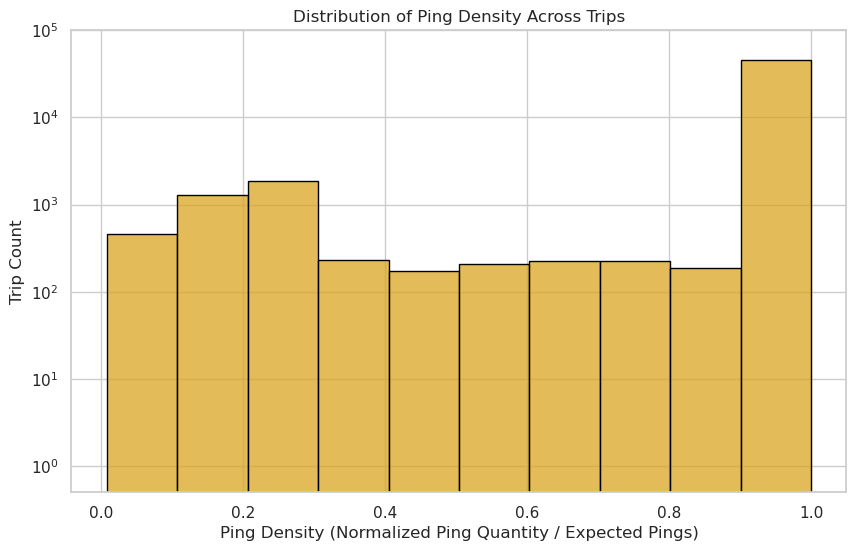

In [12]:
plt.figure(figsize=(10, 6))

sns.histplot(
    data=trip_stats,
    x="ping_density",
    bins=10,
    color="goldenrod",
    edgecolor="black"
)

plt.yscale("log")
plt.ylim(0.5, 100000)

plt.xlabel("Ping Density (Normalized Ping Quantity / Expected Pings)")
plt.ylabel("Trip Count")
plt.title("Distribution of Ping Density Across Trips")

plt.savefig("ping.pdf")
plt.show()

In [13]:
trip_stats = trip_stats.sort_values("min_time")
cutoff = '2026-03-25 00:00:00'
train_df = trip_stats[trip_stats["min_time"] <= cutoff]
test_df = trip_stats[trip_stats["min_time"] > cutoff]

feature_cols = ["rain", "lineId", "timeofday", "dayofweek", "start_lat", "start_lng", "end_lat", "end_lng", "direction"]
X_train, y_train, pesos = train_df[feature_cols], train_df["duration_min"], train_df["ping_density"]
X_test, y_test = test_df[feature_cols], test_df["duration_min"]

In [14]:
# Use XGBRegressor em vez de XGBClassifier
modelo = xgb.XGBRegressor(
    enable_categorical=True,
    tree_method="hist",
    random_state=42,
    max_depth=10,
    n_estimators=100,
    learning_rate=0.2
)

# Agora o treino vai funcionar
modelo.fit(X_train, y_train, sample_weight=pesos)

# Ajustar n_estimators, learning_rate e max_depth corretamente para evitar overfitting.
# Valores recomendados:
# n_estimators - 100 a 1000
# max_depth - 3 a 10
# learning_rate - 0.1 a 0.01
# seed SEMPRE fixa

# Fazendo as previsões
previsoes = modelo.predict(X_test)

# Medindo a performance do modelo de regressão
erro_medio = mean_absolute_error(y_test, previsoes)
r2 = r2_score(y_test, previsoes)

print(f"Mean Absolute Error (MAE): {erro_medio:.2f}")
print(f"R² (Quality of the model): {r2 * 100:.2f}%")
# Salva o modelo no formato nativo do XGBoost
modelo.save_model("modelo.json")

Mean Absolute Error (MAE): 5.46
R² (Quality of the model): 84.04%


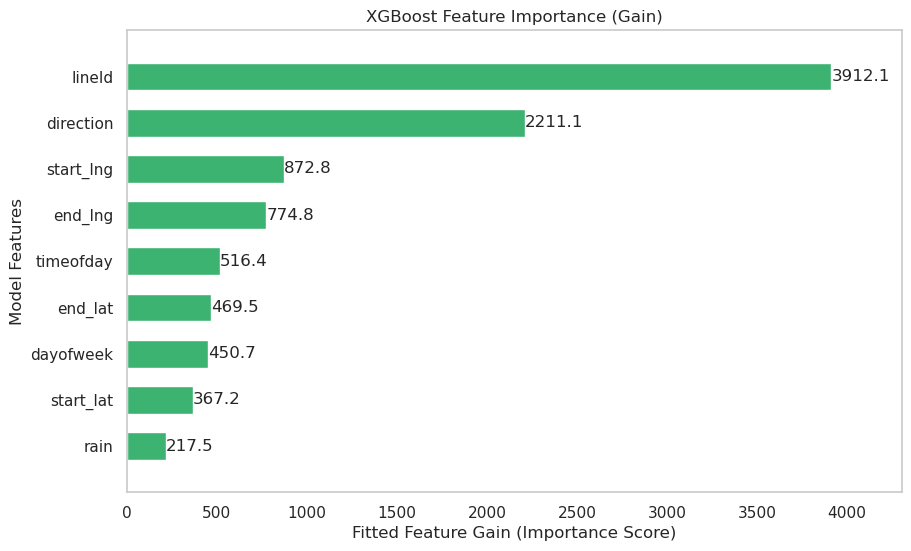

In [15]:
# Gera o gráfico de importância das variáveis
plt.figure(figsize=(10, 6))

ax = xgb.plot_importance(
    modelo,
    importance_type="gain",  # 'weight' (contagem), 'gain' (ganho médio) ou 'cover'
    height=0.6,  # Espessura das barras
    color="mediumseagreen",  # Cor das barras
    grid=False,  # Remove as linhas de grade padrão, se preferir
    ax=plt.gca(),  # Passa o eixo atual para aplicar o figsize
)

for text in ax.texts:
    try:
        val = float(text.get_text())
        text.set_text(f"{val:.1f}") # Altere para ':.0f' caso queira sem nenhuma casa decimal
    except ValueError:
        pass

plt.xlabel("Fitted Feature Gain (Importance Score)")
plt.ylabel("Model Features")
plt.title("XGBoost Feature Importance (Gain)")

# Exibe o gráfico na tela
plt.savefig("feature.pdf")
plt.show()

In [16]:
print(trip_stats["duration_min"].std())
print(5.46/trip_stats["duration_min"].std())

23.404510948624274
0.23328836103370665


In [17]:
print(trip_stats["duration_min"].mean())
print(5.46/trip_stats["duration_min"].mean())

48.007452896812694
0.11373234092914143


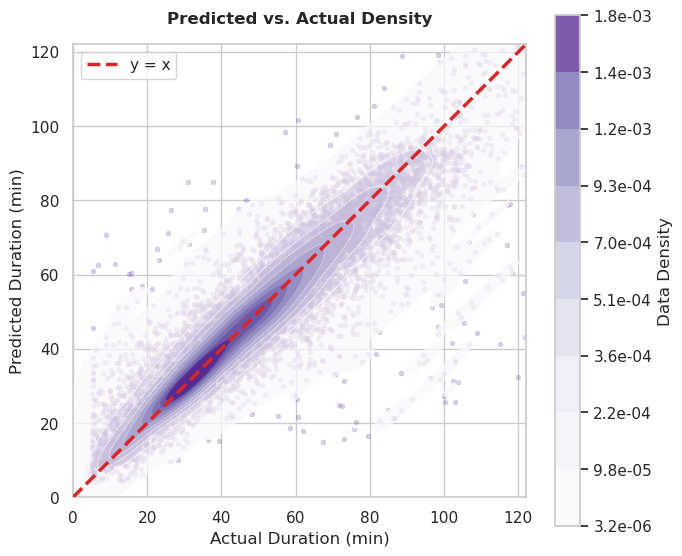

In [18]:
fig, ax = plt.subplots(figsize=(7, 6))

# 1. Scatter plot for global distribution and outliers
sns.scatterplot(
    x=y_test,
    y=previsoes,
    alpha=0.25,
    color="#5e3c99",  # Deep purple matching the KDE palette
    s=12,
    edgecolor=None,
    ax=ax,
)

# 2. KDE density plot with formatted colorbar
sns.kdeplot(
    x=y_test,
    y=previsoes,
    fill=True,
    cmap="Purples",
    alpha=0.75,
    thresh=0.01,
    levels=10,
    cbar=True,
    cbar_kws={
        "label": "Data Density",
        "format": FormatStrFormatter("%.1e"),  # Formats density values (e.g., 1.8e-03)
    },
    ax=ax,
)

# 3. Limits and Reference Line (y = x)
lim_max = np.percentile(y_test, 99.5)
lims = [0, lim_max]

ax.plot(
    lims,
    lims,
    color="#d62728",
    linestyle="--",
    linewidth=2.5,
    label="y = x",
    zorder=5,  # Keeps line on top of density layers
)

# 4. Axes formatting
ax.set_xlim(lims)
ax.set_ylim(lims)
ax.set_aspect("equal", adjustable="box")  # Enforces true 1:1 geometric aspect ratio

# Tick interval control
ax.xaxis.set_major_locator(MultipleLocator(20))
ax.yaxis.set_major_locator(MultipleLocator(20))

ax.set_xlabel("Actual Duration (min)")
ax.set_ylabel("Predicted Duration (min)")
ax.set_title("Predicted vs. Actual Density", pad=15, fontweight="bold")
ax.legend(loc="upper left")

plt.tight_layout()
plt.savefig("predict_atual.pdf", dpi=300)
plt.show()

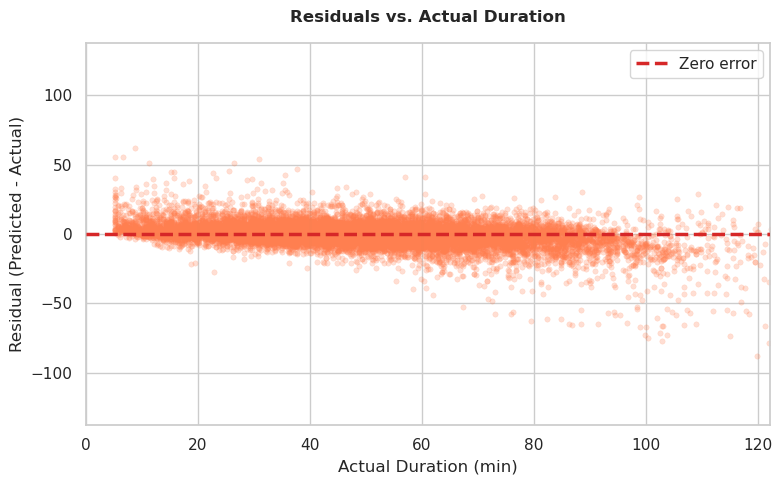

In [19]:
# Calculate residuals
error = previsoes - y_test
fig, ax = plt.subplots(figsize=(8, 5))

# 1. Scatter plot matching the purple theme from the density plot
sns.scatterplot(
    x=y_test, 
    y=error, 
    alpha=0.25,      # Transparency to reveal density in the cluster
    color="coral",
    edgecolor=None,
    s=15,            # Slightly smaller points to reduce overlapping blobs
    ax=ax
)

# 2. Zero-error reference line (brought to the front using zorder)
ax.axhline(
    0, 
    color="#d62728", 
    linestyle="--", 
    linewidth=2.5, 
    label="Zero error",
    zorder=5         # Forces the red line to sit on top of the purple dots
)

# 3. Synchronize X-axis limits with the density plot
lim_max = np.percentile(y_test, 99.5)
ax.set_xlim(0, lim_max)

# Symmetrical Y-axis (Optional but recommended for residuals)
# This forces the zero line to sit exactly in the middle of the vertical space
y_max = np.abs(ax.get_ylim()).max() 
ax.set_ylim(-y_max, y_max)

ax.set_xlabel("Actual Duration (min)")
ax.set_ylabel("Residual (Predicted - Actual)")
ax.set_title("Residuals vs. Actual Duration", pad=15, fontweight="bold")
ax.legend()

plt.tight_layout()
plt.savefig("error.pdf", dpi=300)
plt.show()